**Configuração inicial**

In [1]:
!nvidia-smi
!pip install -q roboflow ultralytics

Thu May 28 00:37:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**Importação das bibliotecas**

In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import shutil
import os
import random
import cv2
import pandas as pd

from ultralytics import YOLO
from roboflow import Roboflow

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


**Conexão com a API Roboflow**

In [ ]:
import os
if not os.environ.get("ROBOFLOW_API_KEY"):
    raise RuntimeError("Configure ROBOFLOW_API_KEY no ambiente antes de baixar o dataset.")
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("yolov8-deteco-e-classificao-de-objetos").project("tema_b")
version = project.version(3)
dataset = version.download("yolov8")

**Verificação do dataset**

In [4]:
print(f"Total de imagens treino: {len(os.listdir(dataset.location + '/train/images/'))}")
print(f"Total de imagens validação: {len(os.listdir(dataset.location + '/valid/images/'))}")
print(f"Total de imagens teste: {len(os.listdir(dataset.location + '/test/images/'))}")

Total de imagens treino: 297
Total de imagens validação: 97
Total de imagens teste: 98


**Treinamento YOLOv8**

Após o treinamento, a Ultralytics YOLOv8 gera automaticamente diversos arquivos e pastas dentro do diretório:

 ->  **runs/detect/runs/train/TEMA_B_Treinado/**.

Nesta pasta, você encontrará todos os outputs do treinamento, incluindo:

* Pesos do modelo (best.pt, last.pt)
* Modelo exportado ONNX (best.onnx) - gerado após executar a exportação, permitindo compatibilidade com diferentes plataformas e aplicações.
* Curvas de performance (BoxF1_curve.png, BoxPR_curve.png, etc.)
* Matriz de confusão (confusion_matrix.png e confusion_matrix_normalized.png)
* Evolução das métricas e losses (results.png)
* Imagens de amostra do treino e da validação (train_batch*.jpg, val_batch0_pred.jpg)

In [5]:
model = YOLO("yolov8s.pt")
# Treinamento
results = model.train(
    data=dataset.location + "/data.yaml",
    epochs=50,
    imgsz=640,
    project="runs/train",
    name="TEMA_B_Treinado",
    device="0",
    verbose=True
)

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/TEMA_B-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=TEMA_B_Treinado, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience

**Captura de Prints / Entregáveis**

Prints salvos em: /content/runs/train/TEMA_B_Treinado/captura_prints


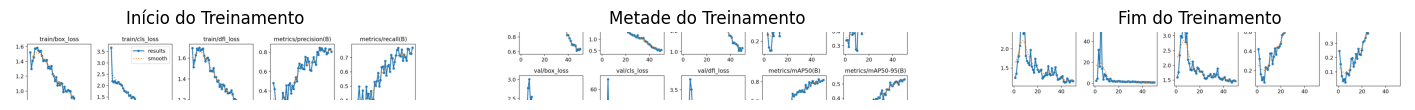

In [8]:
results_path = Path("runs/detect/runs/train/TEMA_B_Treinado/results.png")

# Pasta de destino para salvar os prints
output_dir = Path("runs/train/TEMA_B_Treinado/captura_prints")
output_dir.mkdir(parents=True, exist_ok=True)

# Verifica se o arquivo existe
if results_path.exists():
    im = Image.open(results_path)
    width, height = im.size

    # Divide em 3 partes: início, meio e fim
    inicio = im.crop((0, 0, width, height//3))
    meio = im.crop((0, height//3, width, 2*height//3))
    fim = im.crop((0, 2*height//3, width, height))

    # Salva os prints
    inicio.save(output_dir / "inicio.png")
    meio.save(output_dir / "meio.png")
    fim.save(output_dir / "fim.png")

    print(f"Prints salvos em: {output_dir.resolve()}")
else:
    print("Erro: gráfico de resultados não encontrado. Execute o treinamento primeiro.")

# referência visual rápida
fig, axes = plt.subplots(1, 3, figsize=(18,6))
axes[0].imshow(inicio)
axes[0].set_title("Início do Treinamento")
axes[1].imshow(meio)
axes[1].set_title("Metade do Treinamento")
axes[2].imshow(fim)
axes[2].set_title("Fim do Treinamento")
for ax in axes:
    ax.axis("off")
plt.show()

**Exportação para ONNX e Validação Oficial**

In [9]:
onnx_path = "runs/train/TEMA_B_model/weights/best.onnx"
model.export(format="onnx", imgsz=640, project="runs/onnx", name="TEMA_B_model_onnx")
print(f"Modelo exportado para ONNX em: {onnx_path}")

# Validação oficial com dataset de teste
results_val = model.val(data=dataset.location + "/data.yaml", imgsz=640, batch=16)

# Exibe métricas detalhadas por classe
for i, cls_name in enumerate(results_val.names):
    print(f"{cls_name} -> Precision: {results_val.box.p[i]:.3f}, Recall: {results_val.box.r[i]:.3f}, "
          f"F1: {results_val.box.f1[i]:.3f}, mAP50: {results_val.box.ap50[i]:.3f}, "
          f"mAP50-95: {results_val.box.ap[i]:.3f}")

# Exibe média geral
print(f"Média geral -> Precision: {results_val.box.mp:.3f}, Recall: {results_val.box.mr:.3f}, "
      f"mAP50: {results_val.box.map50:.3f}, mAP50-95: {results_val.box.map:.3f}")

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/train/TEMA_B_Treinado/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 423ms
Prepared 4 packages in 1.71s
Installed 4 packages in 272ms
 + colorama==0.4.6
 + onnx==1.21.0
 + onnxruntime==1.26.0
 + onnxslim==0.1.94

requirements: AutoUpdate success ✅ 3.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.21.0 opset 20

**Inferência em Imagens e Vídeo**

IMPORTANTE:


1.   A pasta video precisa existir antes da execução.

->  TEMA_B-3/video/

2.   O nome do vídeo no código deve coincidir exatamente com o arquivo colocado na pasta.
3. O vídeo final conterá todos os objetos detectados e será salvo como um arquivo MP4 ou AVI, pronto para visualização ou análise posterior.


In [10]:
test_images_path = dataset.location + "/test/images/"
random_image = random.choice(os.listdir(test_images_path))
random_image_path = os.path.join(test_images_path, random_image)

# Executa inferência na imagem
results_img = model.predict(random_image_path, imgsz=640)

# Salva a imagem anotada
output_dir_img = Path("/content/TEMA_B-3/test_output")
output_dir_img.mkdir(parents=True, exist_ok=True)

annotated_img = results_img[0].plot()
annotated_img_bgr = cv2.cvtColor(annotated_img, cv2.COLOR_RGB2BGR)
img_output_path = output_dir_img / f"annotated_{random_image}"
cv2.imwrite(str(img_output_path), annotated_img_bgr)
print(f"Imagem anotada salva em: {img_output_path}")

# PROCESSAMENTO DO VÍDEO
video_input_path = "/content/TEMA_B-3/video/video_test1.mp4"
video_output_path = "/content/TEMA_B-3/video/video_classificado.mp4"

# Captura vídeo
cap = cv2.VideoCapture(video_input_path)
if not cap.isOpened():
    raise FileNotFoundError(f"Não foi possível abrir o vídeo: {video_input_path}")

# Pega tamanho do frame original
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# Define tamanho fixo para YOLO (640x640)
out_size = (640, 640)
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(video_output_path, fourcc, fps, out_size)

frame_count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Redimensiona frame para 640x640
    frame_resized = cv2.resize(frame, out_size)

    # Inferência
    results_frame = model.predict(frame_resized, imgsz=640)

    # Converte frame anotado de RGB -> BGR para salvar
    annotated_frame = results_frame[0].plot()
    annotated_frame_bgr = cv2.cvtColor(annotated_frame, cv2.COLOR_RGB2BGR)

    # Escreve frame no vídeo de saída
    out.write(annotated_frame_bgr)
    frame_count += 1

cap.release()
out.release()
print(f"Vídeo processado ({frame_count} frames) salvo em: {video_output_path}")

from google.colab import files
files.download(video_output_path)


image 1/1 /content/TEMA_B-3/test/images/pessoa_usando_bolsa_ombro10_jpg.rf.478cb9c0e9fc556b85294390254f71e2.jpg: 640x640 1 bolsa, 16.2ms
Speed: 3.0ms preprocess, 16.2ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)
Imagem anotada salva em: /content/TEMA_B-3/test_output/annotated_pessoa_usando_bolsa_ombro10_jpg.rf.478cb9c0e9fc556b85294390254f71e2.jpg

0: 640x640 1 oculos, 16.2ms
Speed: 3.8ms preprocess, 16.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 oculos, 16.3ms
Speed: 3.7ms preprocess, 16.3ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 oculos, 1 relogio, 16.3ms
Speed: 2.6ms preprocess, 16.3ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 oculos, 1 relogio, 16.9ms
Speed: 2.6ms preprocess, 16.9ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 oculoss, 1 relogio, 16.2ms
Speed: 2.8ms preprocess, 16.2ms inference, 1.5ms postprocess 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Entregaveis - Modelo(baixar) e relatório info**

In [11]:
# Métricas de Validação
tabela1 = pd.DataFrame({
    "Classe": list(results_val.names.values()) + ["all"],
    "Precision": list(results_val.box.p) + [results_val.box.mp],
    "Recall": list(results_val.box.r) + [results_val.box.mr],
    "mAP50": list(results_val.box.ap50) + [results_val.box.map50],
    "mAP50-95": ["N/A"]*len(results_val.names) + [results_val.box.map],
    "Observação": [""]*len(results_val.names) + ["média geral"]
})
display(tabela1)

,Classe,Precision,Recall,mAP50,mAP50-95,Observação
0,bolsa,0.783440,0.666667,0.752906,N/A,
1,oculos,0.762964,0.847826,0.862411,N/A,
2,relogio,0.870703,0.794118,0.839850,N/A,
3,all,0.805703,0.769537,0.818389,0.534903,média geral


**Exemplo de Imagem |  Alta e Baixa Acurácia**

In [12]:
output_dir_acc = Path("/content/TEMA_B-3/acuracia")
output_dir_acc.mkdir(parents=True, exist_ok=True)

test_images_path = dataset.location + "/test/images/"
all_images = os.listdir(test_images_path)

high_acc_image = random.choice(all_images)

low_acc_image = random.choice(all_images)

# --- Inferência e salvamento da imagem de alta acurácia ---
results_high = model.predict(os.path.join(test_images_path, high_acc_image), imgsz=640)
annotated_high = results_high[0].plot()
high_out_path = output_dir_acc / "high_accuracy_example.jpg"
cv2.imwrite(str(high_out_path), cv2.cvtColor(annotated_high, cv2.COLOR_RGB2BGR))
print(f"Imagem de alta acurácia salva em: {high_out_path}")

# --- Inferência e salvamento da imagem de baixa acurácia ---
results_low = model.predict(os.path.join(test_images_path, low_acc_image), imgsz=640)
annotated_low = results_low[0].plot()
low_out_path = output_dir_acc / "low_accuracy_example.jpg"
cv2.imwrite(str(low_out_path), cv2.cvtColor(annotated_low, cv2.COLOR_RGB2BGR))
print(f"Imagem de baixa acurácia salva em: {low_out_path}")


image 1/1 /content/TEMA_B-3/test/images/pessoa_usando_oculos_grau16_jpg.rf.a96f9db97740a781c5f07b555aef52b7.jpg: 640x640 2 oculoss, 19.1ms
Speed: 4.5ms preprocess, 19.1ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)
Imagem de alta acurácia salva em: /content/TEMA_B-3/acuracia/high_accuracy_example.jpg

image 1/1 /content/TEMA_B-3/test/images/smartwatch_parcialmente-_escondido8_jpg.rf.7f09500204ff71bdfc63c78e63ef90a7.jpg: 640x640 2 relogios, 16.2ms
Speed: 2.9ms preprocess, 16.2ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Imagem de baixa acurácia salva em: /content/TEMA_B-3/acuracia/low_accuracy_example.jpg
